# Global Innovation Index 2026: the Middle East and the rest of the world

**Question:** Where does each Middle East economy rank in the Global Innovation Index 2026, which moved up since 2025, and how does the region compare with the rest of the world?

This notebook rebuilds the processed tables from the raw readings, recomputes the headline figures from the tidy table and checks they match the build script output.

In [1]:
import os, sys, base64
import pandas as pd
sys.path.insert(0, 'scripts')
import build_data
df = build_data.build()
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0].to_string())

(139, 16)
income_group_rank_2026    2
score_2025                3
rank_2025                 3
check_2025                3
rank_change               3
score_change              3


## Data checks
Row count, duplicates, value ranges and coverage by region. The build script has already stopped on any difference between the two readings of the 2026 table, any 2025 difference not listed, any rank out of order with its score, and any published figure that disagrees.

In [2]:
assert len(df) == 139 and not df.iso3.duplicated().any()
assert df.score_2026.between(0, 100).all()
print(df.groupby('region', observed=True).size().to_string())
print(df.rank_check_2026.value_counts().to_string())
print(df.check_2025.value_counts(dropna=False).to_string())

region
Middle East       15
Europe            40
Rest of Asia      28
Rest of Africa    31
North America     13
South America     10
Oceania            2
rank_check_2026
two-documents              77
one-document-read-twice    62
check_2025
two-documents     131
sources-differ      5
NaN                 3


## Middle East, Gulf first

In [3]:
me = df[df.region == 'Middle East']
print(me[['sub_region', 'country', 'score_2026', 'rank_2026', 'rank_2025', 'rank_change']].to_string(index=False))

            sub_region              country  score_2026  rank_2026  rank_2025  rank_change
       Levant and Iraq               Israel        52.2         15       14.0         -1.0
                  Gulf United Arab Emirates        46.4         25       30.0          5.0
                  Gulf         Saudi Arabia        37.9         42       46.0          4.0
Iran, Turkey and Yemen               Turkey        37.5         45       43.0         -2.0
                  Gulf                Qatar        36.6         47       48.0          1.0
          North Africa              Morocco        32.8         54       57.0          3.0
       Levant and Iraq               Jordan        31.5         60       65.0          5.0
                  Gulf               Kuwait        30.9         62       73.0         11.0
                  Gulf              Bahrain        30.8         64       62.0         -2.0
                  Gulf                 Oman        30.0         69       69.0          0.0

## Headline figures, recomputed from the tidy table

In [4]:
world_mean = df.score_2026.mean()
me_mean = me.score_2026.mean()
up = int((me.rank_change > 0).sum()); down = int((me.rank_change < 0).sum()); same = int((me.rank_change == 0).sum())
top = df.loc[df.rank_change.idxmax()]
above = me[me.score_2026 > world_mean].country.tolist()
print(f'World mean score 2026: {world_mean:.2f}')
print(f'Middle East mean score 2026: {me_mean:.2f} ({len(me)} economies)')
print(f'Middle East moved up / down / unchanged: {up} / {down} / {same}')
print(f'Largest climb of any economy: {top.country}, {int(top.rank_2025)} to {int(top.rank_2026)}')
print(f'Middle East economies above the world mean: {len(above)}: {above}')
print(f'Middle East economies in the top 50: {int((me.rank_2026 <= 50).sum())}')
s = pd.read_csv('data/processed/region_summary.csv').set_index('group')
assert round(world_mean, 2) == s.loc['World', 'mean_score_2026']
assert round(me_mean, 2) == s.loc['Middle East', 'mean_score_2026']
assert (up, down, same) == (s.loc['Middle East', 'moved_up'], s.loc['Middle East', 'moved_down'], s.loc['Middle East', 'unchanged'])
assert top.country == 'Kuwait' and (df.rank_change == top.rank_change).sum() == 1
print('Headline figures match the build script output.')

World mean score 2026: 32.32
Middle East mean score 2026: 33.05 (15 economies)
Middle East moved up / down / unchanged: 10 / 4 / 1
Largest climb of any economy: Kuwait, 73 to 62
Middle East economies above the world mean: 6: ['Israel', 'United Arab Emirates', 'Saudi Arabia', 'Turkey', 'Qatar', 'Morocco']
Middle East economies in the top 50: 5
Headline figures match the build script output.


## Alternative grouping: WIPO's own region
WIPO groups 18 economies as Northern Africa and Western Asia. It adds Cyprus, Georgia, Armenia and Azerbaijan and leaves out Iran. The result under both groupings:

In [5]:
print(s.loc[['Middle East', 'Northern Africa and Western Asia (WIPO)'], ['economies', 'mean_score_2026', 'moved_up', 'moved_down', 'unchanged', 'in_top_50']].to_string())

                                         economies  mean_score_2026  moved_up  moved_down  unchanged  in_top_50
group                                                                                                          
Middle East                                     15            33.05        10           4          1          5
Northern Africa and Western Asia (WIPO)         18            33.50        11           5          2          6


## Scores across editions
Most scores rose between the two editions, so a change in score partly reflects the edition. Rank is the fairer comparison.

In [6]:
c = df.dropna(subset=['score_2025'])
print(f'{len(c)} economies in both editions; mean score change {c.score_change.mean():.2f}; rose {(c.score_change > 0).sum()}, fell {(c.score_change < 0).sum()}, unchanged {(c.score_change == 0).sum()}')

136 economies in both editions; mean score change 0.88; rose 110, fell 23, unchanged 3


## Regions

In [7]:
print(s[s.level.isin(['world', 'region'])][['economies', 'mean_score_2026', 'median_rank_2026', 'best', 'best_rank', 'in_top_50']].to_string())

                economies  mean_score_2026  median_rank_2026           best  best_rank  in_top_50
group                                                                                            
World                 139            32.32              70.0    Switzerland          1         50
Middle East            15            33.05              62.0         Israel         15          5
Europe                 40            43.42              31.5    Switzerland          1         31
Rest of Asia           28            33.46              72.5    South Korea          4          9
Rest of Africa         31            19.20             121.0      Mauritius         50          1
North America          13            28.49              91.0  United States          3          2
South America          10            26.19              79.0          Chile         51          0
Oceania                 2            48.00              22.0      Australia         20          2


## Charts

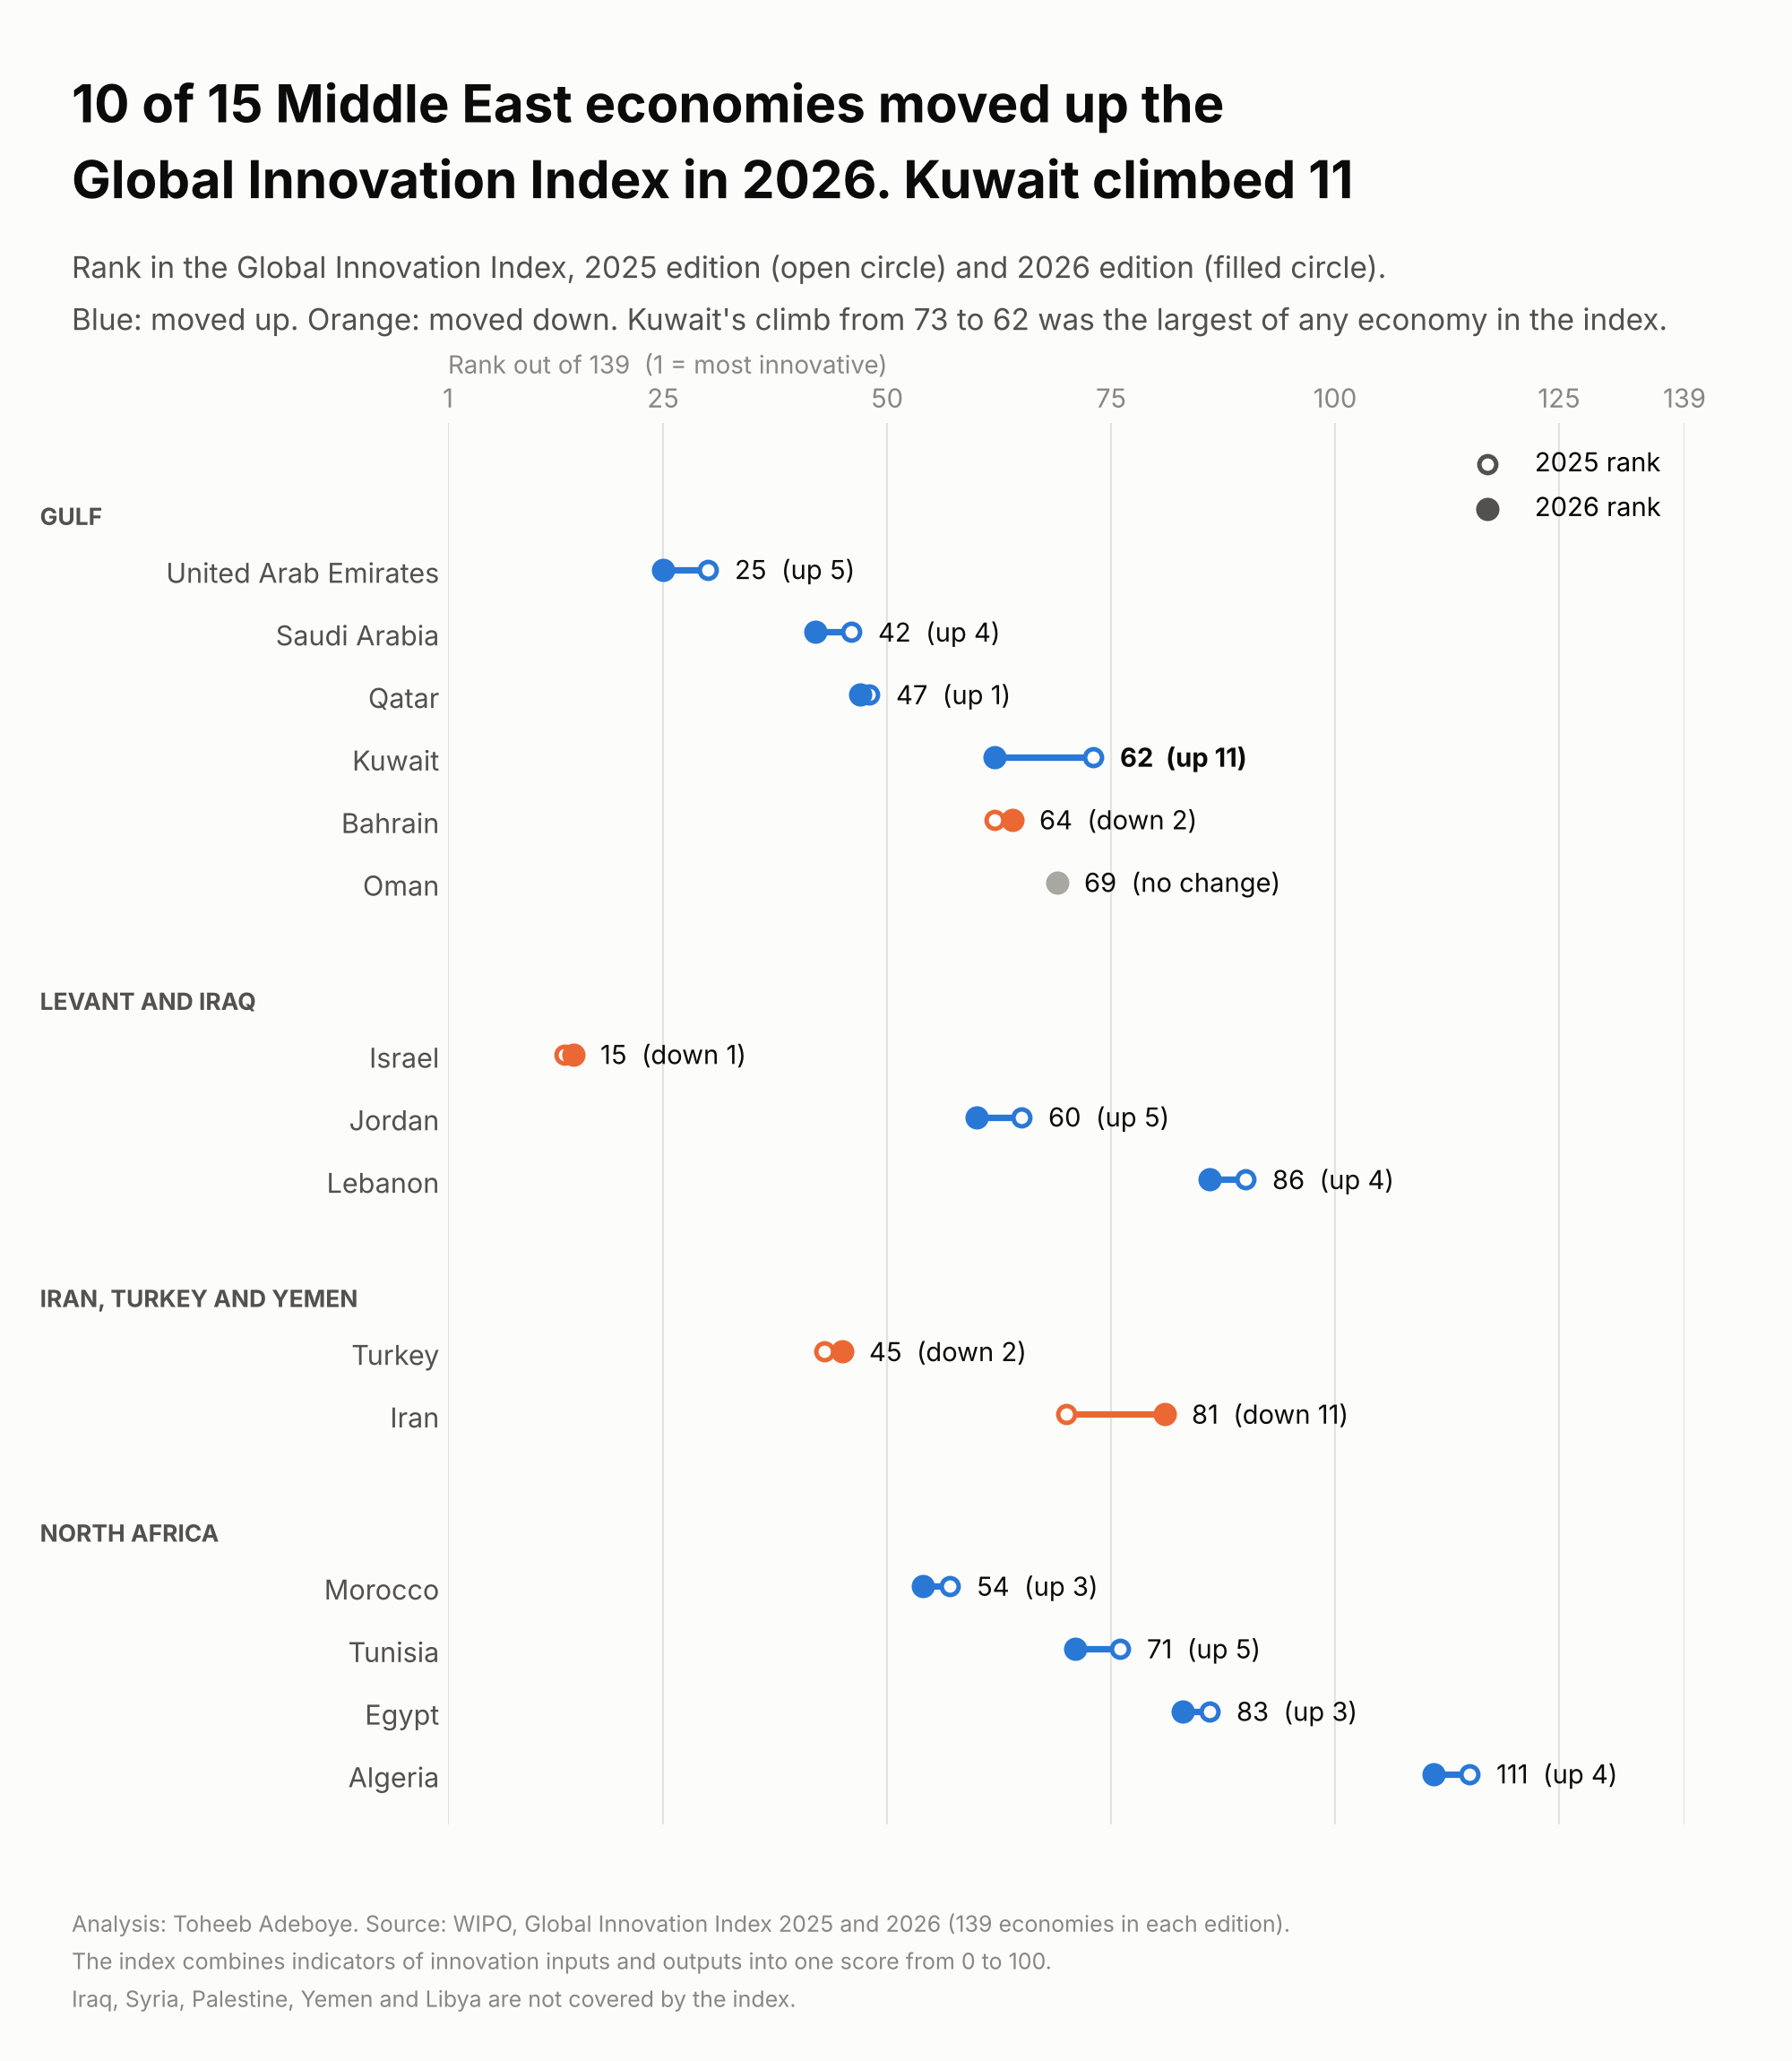

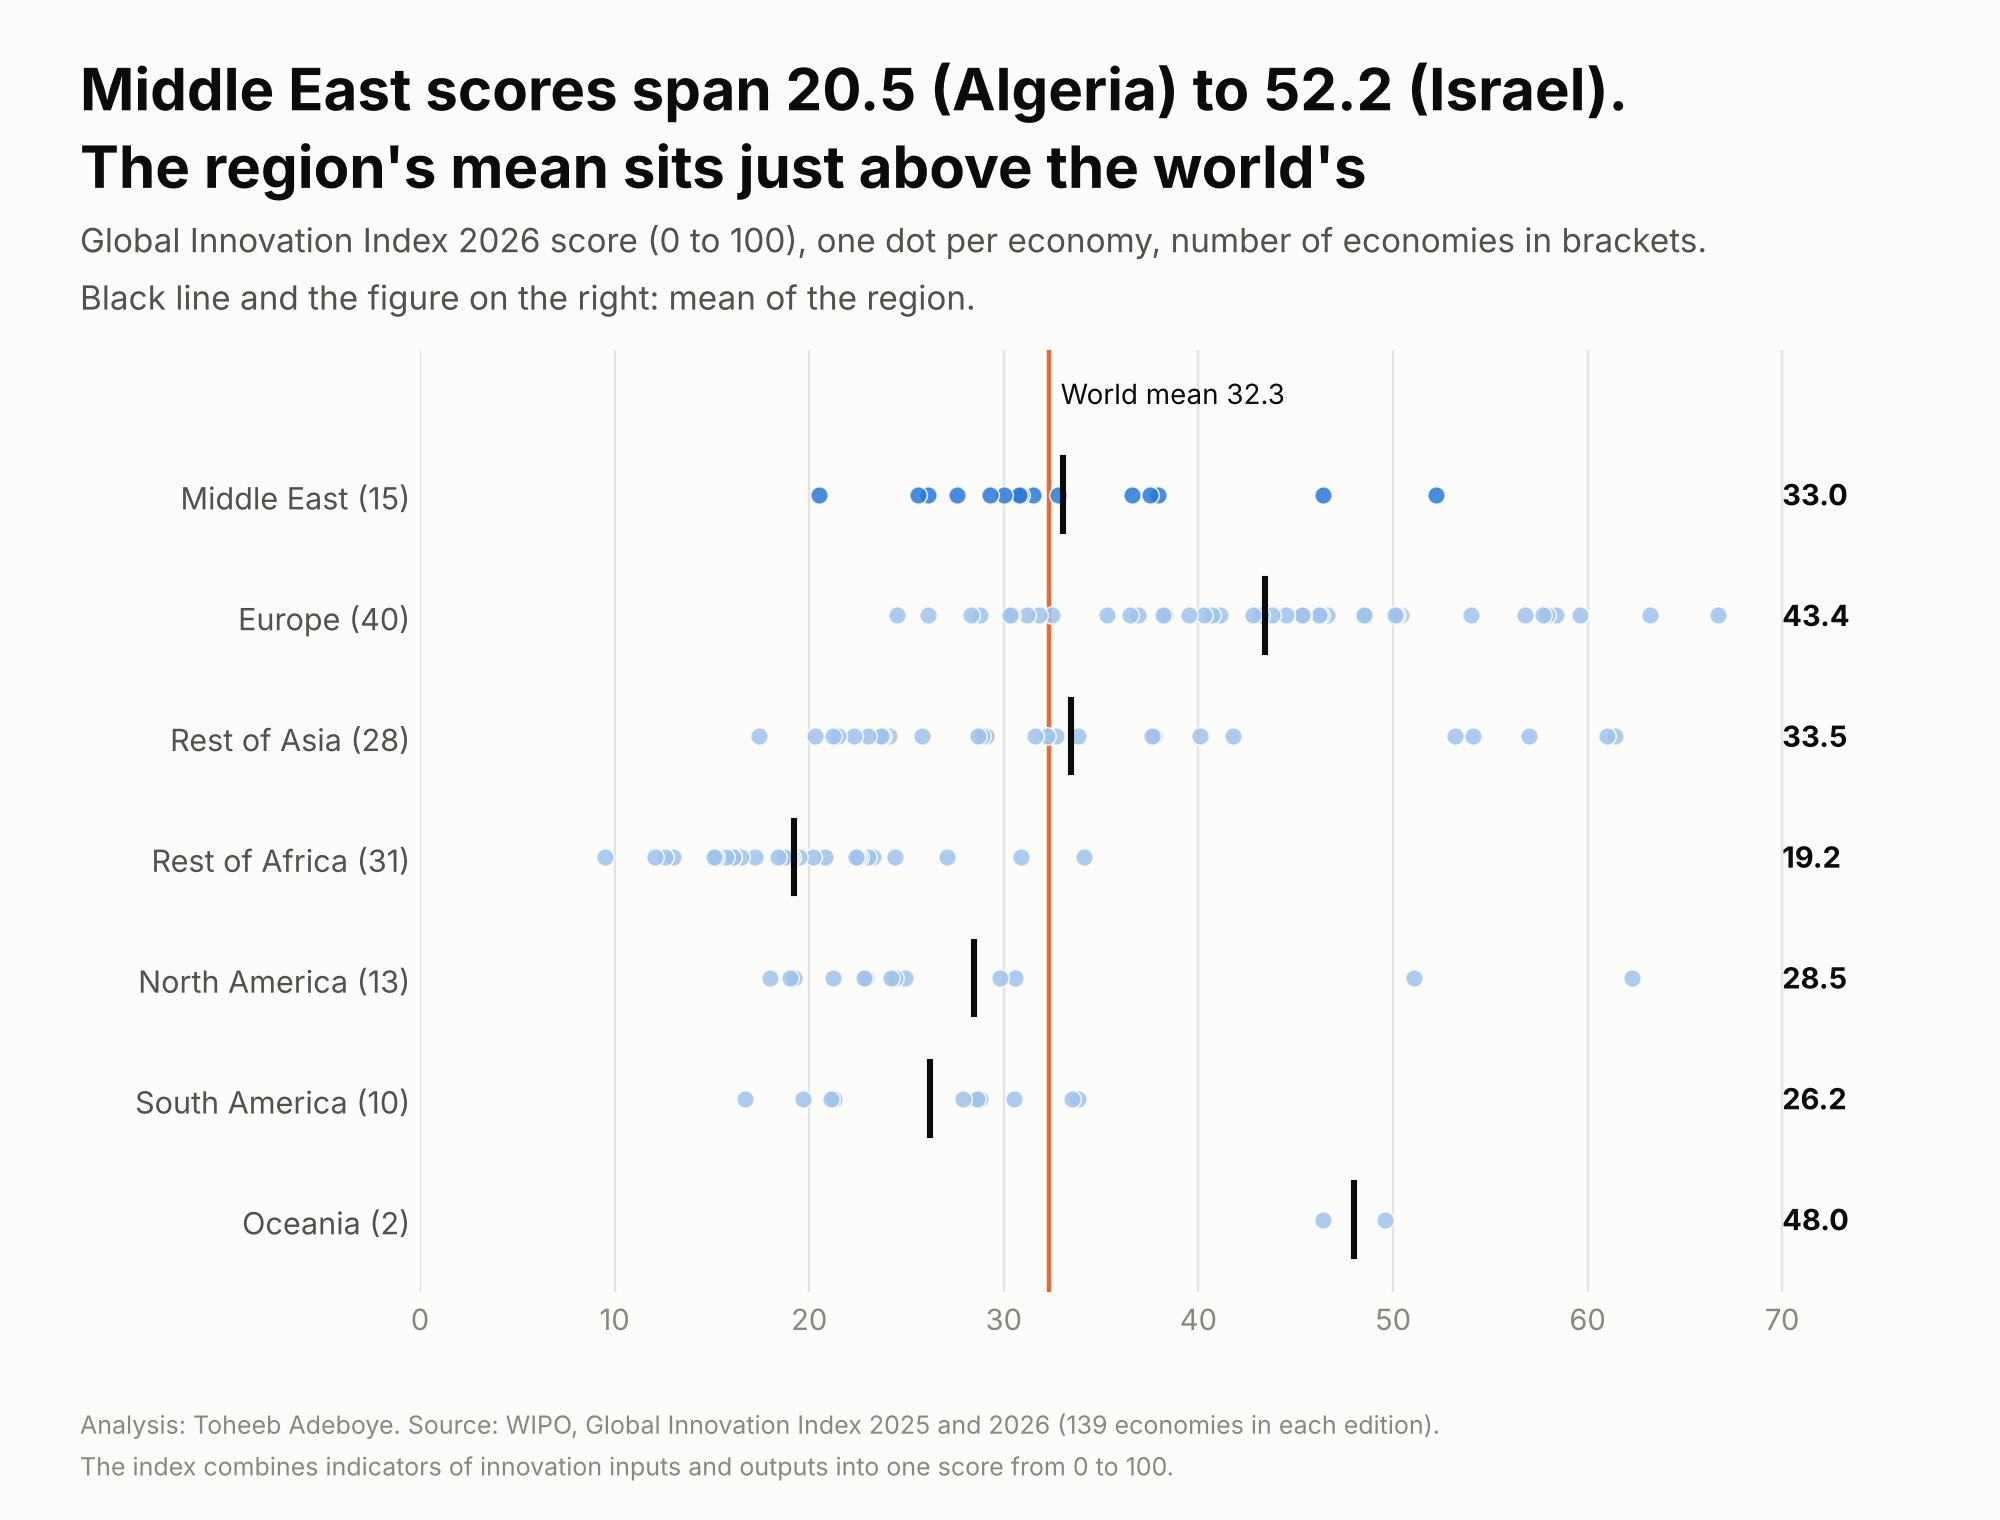

In [8]:
from IPython.display import Image, display
import make_charts
make_charts.middle_east_chart(); make_charts.region_chart()
for f in ['images/innovation-middle-east-chart.png', 'images/innovation-score-by-region.png']:
    display(Image(filename=f))